# 06 - KNN Hyperparameter Tuning


Best k for KNN: 3


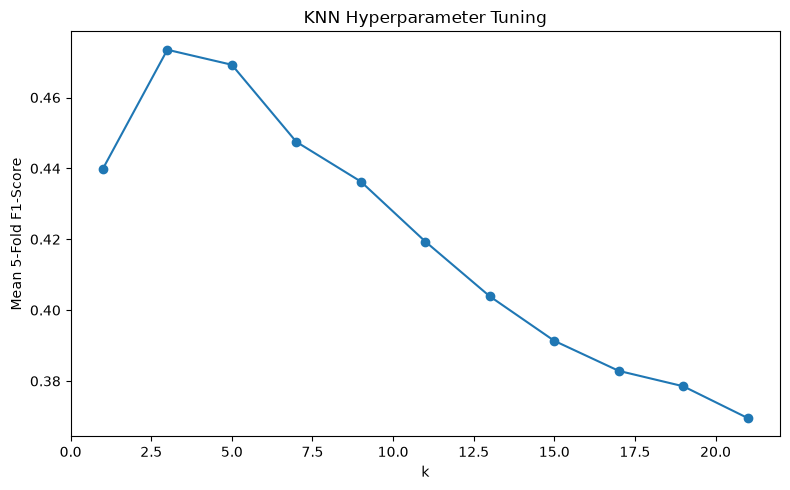

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('online_shoppers_intention.csv')
df = df.drop_duplicates().copy()
df['Weekend'] = df['Weekend'].astype(int)
df['Revenue'] = df['Revenue'].astype(int)

df['Total_Pages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['Total_Duration'] = (
    df['Administrative_Duration'] +
    df['Informational_Duration'] +
    df['ProductRelated_Duration']
)

df = pd.get_dummies(
    df,
    columns=['Month', 'VisitorType'],
    drop_first=True,
    dtype=int
)

X = df.drop('Revenue', axis=1)
y = df['Revenue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)

k_values = list(range(1, 22, 2))
knn_scores = []

for k in k_values:
    score = cross_val_score(
        KNeighborsClassifier(n_neighbors=k),
        X_train_s,
        y_train,
        cv=5,
        scoring='f1'
    ).mean()
    knn_scores.append(score)

best_k = k_values[np.argmax(knn_scores)]
print('Best k for KNN:', best_k)

plt.figure(figsize=(8, 5))
plt.plot(k_values, knn_scores, marker='o')
plt.xlabel('k')
plt.ylabel('Mean 5-Fold F1-Score')
plt.title('KNN Hyperparameter Tuning')
plt.tight_layout()
plt.show()
